In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

combined_df = pd.read_csv(os.path.join("Filterd datasets", "traindata_filtered_2024.csv"))

In [2]:
delays_saturdays = combined_df.groupby('Service:Date')['Stop:Arrival delay'].sum().reset_index() 
delays_saturdays.columns = ['Date', 'Total_Delay_Minutes']

delays_saturdays

,Date,Total_Delay_Minutes
0,2024-01-06,29974.0
1,2024-01-13,37770.0
2,2024-01-20,34996.0
3,2024-01-27,39300.0
4,2024-02-03,38504.0
5,2024-02-10,41129.0
6,2024-02-17,32783.0
7,2024-02-24,33896.0
8,2024-03-02,33354.0
9,2024-03-09,29576.0


In [3]:
#Calculation of delays on Saturdays in 2024 

average_delay = delays_saturdays['Total_Delay_Minutes'].mean()
print(f"The average total delay on Saturdays in 2024 is: {average_delay:.2f} minutes.")

number_above_mean = (delays_saturdays['Total_Delay_Minutes'] > average_delay).sum()
print(f"Number of Saturdays with a total delay above the average: {number_above_mean}")

delay_kings_day = delays_saturdays.loc[delays_saturdays['Date'] == '2024-04-27', 'Total_Delay_Minutes'].iloc[0]
number_above_kings_day = (delays_saturdays['Total_Delay_Minutes'] > delay_kings_day).sum()
print(f"Number of Saturdays with a total delay above that of April 27, 2024: {number_above_kings_day}")

percentage_above_mean = ((delay_kings_day - average_delay) / average_delay) * 100
print(f"The total delay on King's Day is {percentage_above_mean:.2f}% above the average delay on Saturdays.")



The average total delay on Saturdays in 2024 is: 37162.00 minutes.
Number of Saturdays with a total delay above the average: 21
Number of Saturdays with a total delay above that of April 27, 2024: 3
The total delay on King's Day is 32.75% above the average delay on Saturdays.


C:\Users\jiska\AppData\Local\Temp\ipykernel_25452\2447265859.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


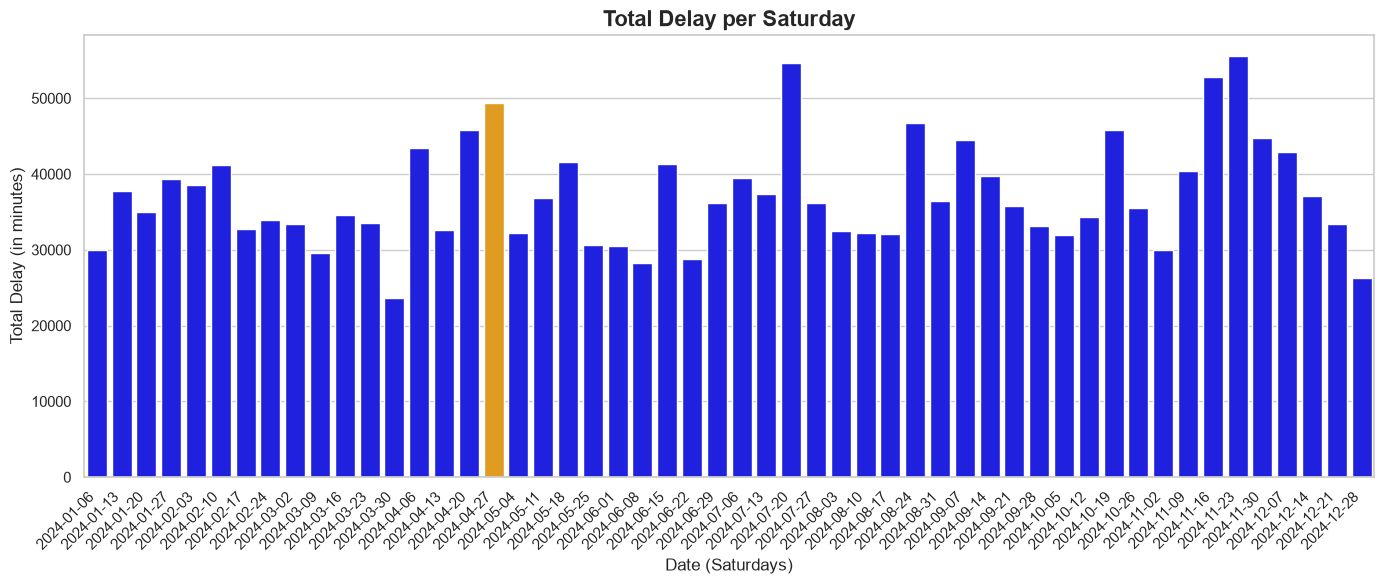

In [ ]:
#Visualisation delay per saturday in 2024 
plt.figure(figsize=(14, 6))
colors = ["orange" if str(datum).startswith("2024-04-27") else "blue" for datum in delays_saturdays["Date"]]

ax = sns.barplot(
    x="Date",
    y="Total_Delay_Minutes",
    data=delays_saturdays,
    palette=colors,
)

plt.title("Total Delay per Saturday", fontsize=16, fontweight="bold")
plt.xlabel("Date (Saturdays)", fontsize=12)
plt.ylabel("Total Delay (in minutes)", fontsize=12)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


In [9]:
#Check if there are outliers in the data by filtering out delays greater than 60 minutes 
df_filtered = combined_df[combined_df['Stop:Arrival delay'] <= 60]

delays_saturdays_outlier = df_filtered.groupby('Service:Date')['Stop:Arrival delay'].sum().reset_index()
delays_saturdays_outlier.columns = ['Date', 'Total_Delay_Minutes']



C:\Users\jiska\AppData\Local\Temp\ipykernel_25452\2528570988.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\jiska\AppData\Local\Temp\ipykernel_25452\2528570988.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


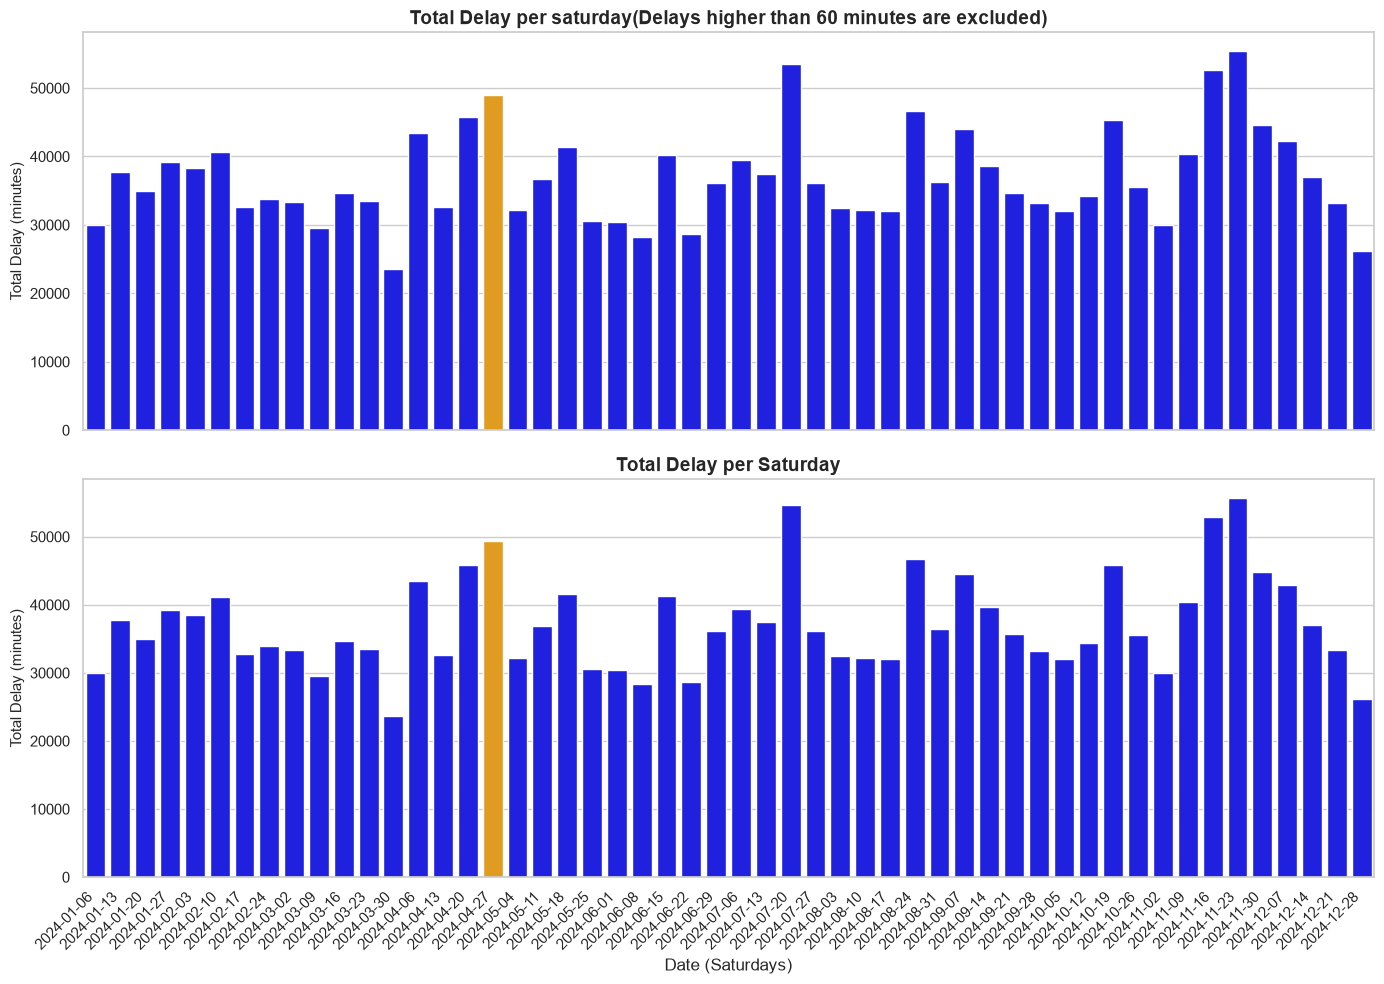

In [10]:
#Plot outliers and non-outliers in two separate graphs for comparison 
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
colors_1 = ["orange" if str(datum).startswith("2024-04-27") else "blue" for datum in delays_saturdays_outlier["Date"]]

sns.barplot(
    x="Date",
    y="Total_Delay_Minutes",
    data=delays_saturdays_outlier,
    palette=colors_1,
    ax=axes[0],
)
axes[0].set_title("Total Delay per saturday(Delays higher than 60 minutes are excluded)",fontsize=14,fontweight="bold")
axes[0].set_ylabel("Total Delay (minutes)", fontsize=11)
axes[0].set_xlabel("")  


colors_2 = ["orange" if str(datum).startswith("2024-04-27") else "blue" for datum in delays_saturdays["Date"]]

sns.barplot(
    x="Date",
    y="Total_Delay_Minutes",
    data=delays_saturdays,
    palette=colors_2,
    ax=axes[1], 
)
axes[1].set_title("Total Delay per Saturday", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Total Delay (minutes)", fontsize=11)
axes[1].set_xlabel("Date (Saturdays)", fontsize=12)



plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


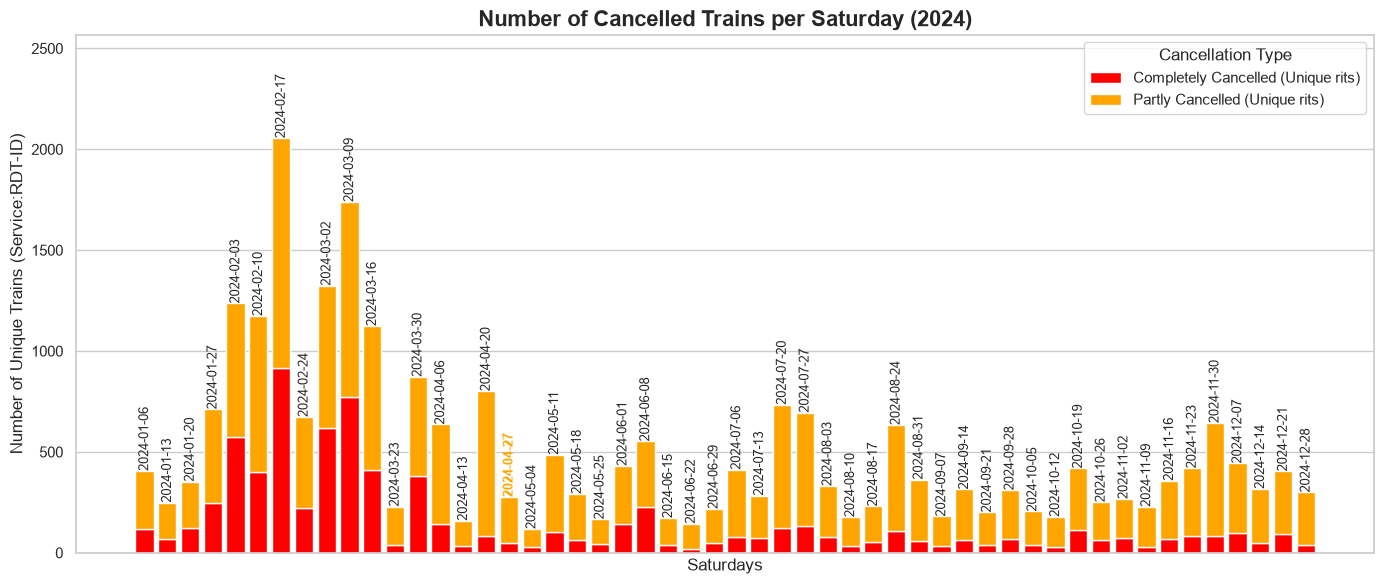

In [20]:
#Look at cancellations per Saturday in 2024 
combined_df["Service:Date"] = pd.to_datetime(combined_df["Service:Date"])

cancellations_df = (
    combined_df.groupby("Service:Date")
    .apply(
        lambda x: pd.Series(
            {
                "Completely_Cancelled": x.loc[
                    x["Service:Completely cancelled"] == True, "Service:RDT-ID"
                ].nunique(),
                "Partly_Cancelled": x.loc[
                    x["Service:Partly cancelled"] == True, "Service:RDT-ID"
                ].nunique(),
            }
        )
    )
    .reset_index()
)

# Calculate the total cancellations per Saturday 
cancellations_df["Total_Cancelled"] = (cancellations_df["Completely_Cancelled"]+ cancellations_df["Partly_Cancelled"])
cancellations_df = cancellations_df.sort_values(by="Service:Date")
cancellations_df["Date_Str"] = (cancellations_df["Service:Date"].dt.date.astype(str))


# Make a bar plot 
fig, ax = plt.subplots(figsize=(14, 6))


bars1 = ax.bar(
    cancellations_df["Date_Str"],
    cancellations_df["Completely_Cancelled"],
    label="Completely Cancelled (Unique rits)",
    color = "red"
)
bars2 = ax.bar(
    cancellations_df["Date_Str"],
    cancellations_df["Partly_Cancelled"],
    bottom=cancellations_df["Completely_Cancelled"],
    label="Partly Cancelled (Unique rits)",
    color= "orange", 
)


dates = cancellations_df["Date_Str"]

labels = ax.bar_label(bars2, labels=dates, rotation=90,fontsize=9)

for label, date in zip(labels, dates):
    if date == "2024-04-27":
        label.set_color("orange")
        label.set_fontweight("bold")

ax.set_xticks([])
ax.set_ylim(0, cancellations_df["Total_Cancelled"].max() * 1.25) 

plt.title("Number of Cancelled Trains per Saturday (2024)",fontsize=16,fontweight="bold")
plt.ylabel("Number of Unique Trains (Service:RDT-ID)", fontsize=12)
plt.xlabel("Saturdays", fontsize=12)
plt.legend(title="Cancellation Type")

plt.tight_layout()
plt.show()
